# Exercise 7: Autocorrelation and radial distribution function
### Ex. 7.1: Tail corrections
  > ***goal**: include tail corrections to $U$ and $p$.*

During the simulation parameters reading for the LJ system, we can also compute the tail correction values, saved as private members of the `LJSystem` class:

```cpp
vtail = 8 * pi * _rho * _epsilon *
        (1 / (9 * std::pow(_r_cut, 9.0)) - 1 / (3 * std::pow(_r_cut, 3.0)));
_ptail = 32 * pi * _rho *
         (1 / (9 * std::pow(_r_cut, 9.0)) - 1 / (6 * std::pow(_r_cut, 3.0)));
```

after having read $N_{part}$, $\rho^*$, $\epsilon$ and $r^*_{cut}$.

Then they simply are added to the computation of $U/N$ and $p$: the first is computed in `LJSystem::measure()` and then passed to multiple measurables ($U / N$, $E_{tot}$):

```cpp
void LJSystem::measure() {
  double k = 0.0, u = 0.0, virial = 0.0;
  std::vector<double> distances, speeds;

  for (int i = 0; i < _npart; i++) {
    double v = mod(_particles(i).get_v());
    speeds.emplace_back(v);
    k += 0.5 * _m * v * v;

    for (int j = i + 1; j < _npart; j++) {
      double r =
          _nearest_image_dist(_particles(i).get_x(), _particles(j).get_x());
      distances.emplace_back(r);
      if (r >= _r_cut)
        u += 4.0 * _epsilon *
             (std::pow(_sigma / r, 12.0) - std::pow(_sigma / r, 6.0));
      virial += 4.0 * _epsilon *
                (std::pow(_sigma / r, 12.0) - 0.5 * std::pow(_sigma / r, 6.0));
    }
  }

  k /= _npart;
  u = u / _npart + _vtail;

  std::array<double, 3> args{k, u, virial};
  for (auto &measurable : _measurables) {
    measurable.measure(args);
  }
  _gofr->measure(distances);
  _pofv->measure(speeds);
}
```

while `_ptail` is used in the `_compute` method of the pressure `Measurable` object, when building the `_measurables` vector for an LJ system:

```cpp
_measurables.emplace_back(
    "pressure", /* computes pressure at each step,
                     block estimate is its average */
    [this](std::span<const double> args) {
      double k = args[0], virial = args[2];
      return (2.0 / 3.0) * _rho * k +
             (_ptail * _npart + 4.0 * virial) / _volume + _ptail;
    });
```

### Ex. 7.2: Autocorrelation
  > ***goal**: measure *instantaneous* values of $U / N$ and plot its autocorrelation functions, to estimate the correct block size.*
  > *Use the same data to plot the statistical uncertainty of $U / N$ as a function of blocks size*
> 
> Perform the simulations for $5\cdot 10^{5}$ steps in a LJ liquid phase:
> $$
> \rho^* = 0.8 \quad\text{, }\quad T^* = 1.1
> $$
> using $r^*_{cut} = 2.5$ and, for MD, $\mathrm{d}t^* = 10^{-3}$.
> 
> ***remember:***
>   - *perform the simulation in both MC ($NVT$) and MD ($NVE$) modes, and remember to let the system equilibrate*
>   - *for the MC simulation set $\delta t$ in order to have an acceptance ratio of roughly $r \simeq 0.5$*
>   - *for the MD simulation, calibrate the initial $T$ parameter so that, after equilibration, the system stabilizes at the desired temperature.*


Instead of running multiple simulations to manually calibrate the equilibration time, we can automate the equilibration adding a `Monitor` class to any `System` object:

```cpp
class Monitor {
private:
  int _blocks_window = 16;
    /* acceptance ratio monitoring to adjust _delta */
  int _nattempted = 0, _naccepted = 0;
  double _acceptance_ratio = 0.0;
  double _acceptance_target = 0.5;
  double _acceptance_tolerance = 0.05;
    /* istantaneous measures of a selected observable
     * to detect equilibration */
  std::vector<double> _inst_measures;
  std::vector<double> _block_avgs, _block_vars;
  std::pair<double, double> _lin_reg_slope() const;
  double _m = 0.0, _m_err = 1.0;
  double _slope_stdev_precision = 2.0;
    /* temperature correction */
  std::vector<double> _temps_block;
    /* autocorrelation */
  double _autocorrelation_time() const;

public:
  Monitor() = default;
  Monitor(int, double, bool, double, double, double);
    /* acceptance ratio monitoring to adjust _delta */
  bool auto_mc_parameters = false;
  void naccepted_up(), nattempted_up();
  double get_acc_ratio() const;
  double get_acc_target() const;
  bool is_acc_ratio_ok() const;
    /* equilibration check */
  bool auto_equilibration = false;
  double get_m() const;
  double get_m_err() const;
  bool is_at_equilibrium() const;
    /* temperature correction */
  bool auto_temp_correction = false;
  double temp, temp_err = 0.0;
  double temp_target, temp_stdev_acceptance;
  bool is_temp_ok() const;

  void save_measure(double, double);
  void end_block(int);
  int get_correct_nsteps() const;
};
```

This class has 3 purposes:
- receive, from `System`, instantaneous measures of a selected scalar variable ($U / N$, for example): these are progressively block-averaged and a (weighted) linear regression is performed on the last $N_{\text{blocks window}}$ blocks. The resulting slope is checked to be compatible with 0, within a chosen number of standard deviations.
- for MC methods, count accepted/rejected moves and keep track of their ratio at the end of each block. If they are not close enough to $50%$, `System` will modify its parameters (like $\delta x$) accordingly before running the next equilibration block.
- for MD (NVE) methods, temperature (i.e. *kinetic energy per particle*) measurements are taken at each step, its average and statistical error estimate is computed at the end of the block and it's checked if they are compatible with the the target temperature read from the settings file.

***note**: since the initial potential energy of the system could impose a lower limit for the final temperature, for MD (NVE) simulations, the equilibration phase is allowed to change the system's energy by rescaling all velocities by a factor $\sqrt{T_{target} / T_{eff}}$ after each block. This process stops after the equilbration phase.*

When all relevant checks are satisfied (*stability and acceptance ratio for MC, stability and temperature for MD*) after a minimum number of blocks, the equilibration phase is over: simulation parameters are fixed and the actual simulation (with its relevant measurements) starts.

We can now run both simulations, load the results and plot them:

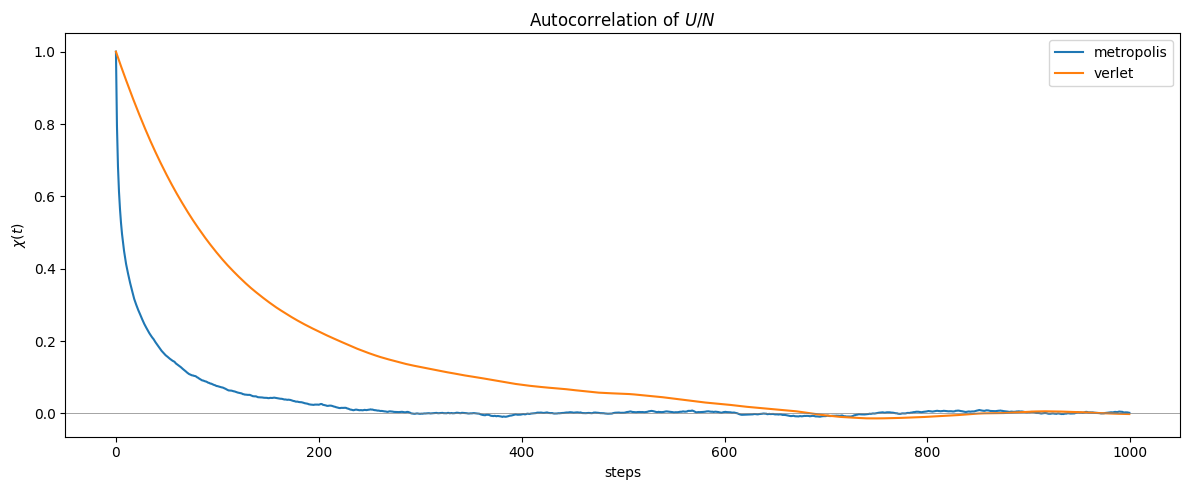

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base_dir = "sim_results/lj_autocorrelation"
methods = ["metropolis", "verlet"]
max_lag = 1000

def load_u(method):
    path = f"{base_dir}/{method}/potential_energy_per_particle.csv"
    df = pd.read_csv(path, header=0, usecols=[1])
    return df.iloc[:, 0].to_numpy(dtype=float)

def autocorrelation(x, max_lag):
    x = np.asarray(x, dtype=float)
    n = len(x)
    x = x - x.mean()
    var = np.mean(x**2)
    chi = np.empty(max_lag)
    for t in range(max_lag):
        chi[t] = np.dot(x[: n - t], x[t:]) / (n - t) / var
    return chi

fig, ax = plt.subplots(figsize=(12, 5))
 
for method in methods:
    u = load_u(method)
    chi = autocorrelation(u, max_lag)
    ax.plot(np.arange(max_lag), chi, label=method)

ax.axhline(0, color="gray", lw=0.5)
#ax.set_xscale("log")
ax.set_xlabel(f"steps")
ax.set_ylabel(r"$\chi (t)$")
ax.set_title("Autocorrelation of $U/N$")
ax.legend()
fig.tight_layout()

We see clearly that the MC run exhibits exponential decay for the autocorrelation function, while the MD data starts to decay as a bell-like curve.

Both of them approach $0$ in roughly the same number of steps (*$100$-$200$ steps*), giving similar decoupling times to decide our block size on.

We then compute and plot the estimate of statistical error as a function of block size:

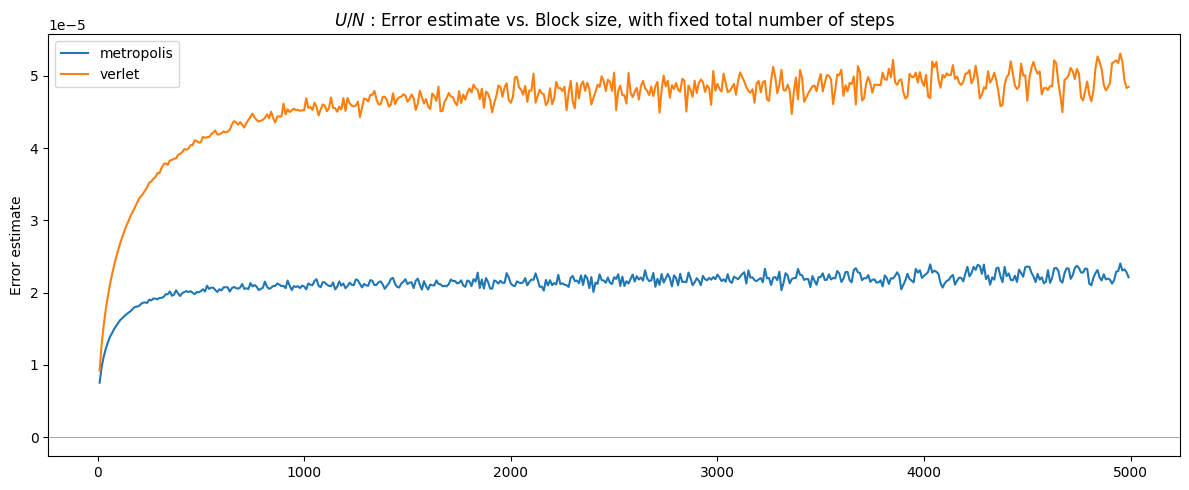

In [2]:
def error_estimate(dataset, block_size):
    n = dataset.size
    nblocks = n // block_size

    blocks_avgs = np.zeros(nblocks)
    for block in range(nblocks):
        block_data = dataset[block*block_size:(block + 1)*block_size]
        blocks_avgs[block] = block_data.mean()

    avg = blocks_avgs.mean()
    blocks_avgs -= avg

    err = np.sum(blocks_avgs**2) / nblocks / (nblocks - 1)
    return np.sqrt(err)

nsteps_min = 10
nsteps_max = int(5e3)

fig, ax = plt.subplots(figsize=(12,5))

block_size_values = np.arange(nsteps_min, nsteps_max)[::10]
for method in methods:
    dataset = load_u(method)

    errs = np.zeros(block_size_values.size)
    for size_id, block_size in enumerate(block_size_values):
        errs[size_id] = error_estimate(dataset, block_size)

    ax.plot(block_size_values, errs, label={method})

ax.axhline(0, color="gray", lw=0.5)
# ax.set_xscale("log")
# ax.set_xlabel("Blocks size [steps, log scale]")
ax.set_ylabel("Error estimate")
ax.set_title("$U / N$ : Error estimate vs. Block size, with fixed total number of steps")
ax.legend()
fig.tight_layout()

### Ex. 7.3: Radial distribution function
  >***goal**: implement the calculation of $g(r)$ radial distribution function*

To measure distributions as histograms, we can write the `MeasurableHistogram` class:

```cpp
class MeasurableHistogram {
  private:
    std::string _name;
    int _n_bins;
    std::vector<double> _block_sum{}, _block_sum_sq{};
    std::vector<double> _global_av{}, _global_av_sq{};
    /* evaluation methods */
    std::function<std::vector<double>(std::span<const double>)> _compute;
    std::function<double(double, double, int)> _block_estimate;
    /* data streams */
    std::ofstream _output_global_stream;
    std::ofstream _output_blocks_stream;

  public:
    MeasurableHistogram(
        std::string, int,
        std::function<std::vector<double>(std::span<const double>)>,
        std::function<double(double, double, int)>);
    MeasurableHistogram(
        std::string, int,
        std::function<std::vector<double>(std::span<const double>)>);
    void measure(std::span<const double>);
    void end_block(int, int);
    void finalize(int);
};
```

of which the `LJSystem` class owns 2 private members `_gofr` and `_pofv`.

For each, the number of histogram bins are read from the settings file, then each object is defined in `LJSystem`'s constructor:

```cpp
_gofr.emplace(
    "gofr", _n_bins_gofr, [this](std::span<const double> distances) {
      std::vector<double> hist(_n_bins_gofr, 0.0);
      for (double r : distances) {
        int bin = static_cast<int>(r / _bin_size_gofr);
        if (bin >= 0 && bin < _n_bins_gofr) {
          double r_lo = bin * _bin_size_gofr, r_hi = r_lo + _bin_size_gofr;
          double shell_volume = 4 * std::numbers::pi *
                                (std::pow(r_hi, 3) + std::pow(r_lo, 3)) / 3.0;
          hist[bin] += 2.0 / (_rho * shell_volume * _npart);
        }
      }
      return hist;
    });
_pofv.emplace("pofv", _n_bins_pofv, [this](std::span<const double> speeds) {
  std::vector<double> hist(_n_bins_pofv, 0.0);
  for (double v : speeds) {
    int bin = static_cast<int>(v / _bin_size_pofv);
    if (bin >= 0 && bin < _n_bins_pofv) {
      hist[bin] += 1.0 / (_npart * _bin_size_pofv);
    }
  }
  return hist;
});
```

setting its name (for output filenames), its number of bins, and the `_compute` member via a lambda.

Then, as with scalar measurables, we have a `measure` call after each simulation step:
  - in `main()` we call `sys->measure()`
  - in `LJSystem::measure` we call `_gofr.measure(std::vector<double>)` and `_pofv.measure(std::vector<double>)` passing their corresponding values of distances and velocities:

```cpp
void LJSystem::measure() {
  /* ... measuring other scalar quantities ... */

  std::vector<double> distances, speeds;

  for (int i = 0; i < _npart; i++) {
    double v = mod(_particles(i).get_v());
    speeds.emplace_back(v);

    for (int j = i + 1; j < _npart; j++) {
      double r =
          _nearest_image_dist(_particles(i).get_x(), _particles(j).get_x());
      distances.emplace_back(r);
    }
  }

  _gofr->measure(distances);
  _pofv->measure(speeds);
}
```

and in each histogram's `measure` call we compute the *instantaneous* histogram measure (using the afore-mentioned `_compute` function) and accumulate it into what will become the block average and the block average of squares:

```cpp
void MeasurableHistogram::measure(std::span<const double> args) {
  std::vector<double> hist = _compute(args);
  for (int bin = 0; bin < _n_bins; bin++) {
    _block_sum[bin] += hist[bin];
    _block_sum_sq[bin] += hist[bin] * hist[bin];
  }
}
```

Then, at the end of each block (within a `sys->end_block()` call), we call `_gofr.end_block(int, int)` and `_pofv.end_block(int, int)`: these convert the histograms filled during the block (of average in values and average bin values squared) into a block estimate of the histogram, using the `_block_estimate` funtcion:

```cpp
void MeasurableHistogram::end_block(int block_number, int n_samples) {
  _output_blocks_stream << block_number + 1 << ",";
  for (int bin = 0; bin < _n_bins; bin++) {
    double bin_block_estimate =
        _block_estimate(_block_sum[bin], _block_sum_sq[bin], n_samples);
    _global_av[bin] += bin_block_estimate;
    _global_av_sq[bin] += bin_block_estimate * bin_block_estimate;

    if (bin < _n_bins - 1) {
      _output_blocks_stream << bin_block_estimate << ",";
    } else {
      _output_blocks_stream << bin_block_estimate << std::endl;
    }

    _block_sum[bin] = 0;
    _block_sum_sq[bin] = 0;
  }
}
```

these block estimates are printed on a file and added to a global `_block_sum` and `_block_sum_sq`, which will, at the end of the simulation, print each bin value with its error on a different file.

### Ex. 7.4: Simulate
  > ***goal**: try these improvements by measuring $U / N$, $p$ and $g(r)$ with*
> $$\begin{align*}
> \text{solid phase} \quad &\rho^* = 1.1 \text{ , }\quad &T^* = 0.8 \quad\text{and}\quad &r^*_{cut} = 2.2 \\
> \text{liquid phase} \quad &\rho^* = 0.8 \text{ , }\quad &T^* = 1.1 \quad\text{and}\quad &r^*_{cut} = 2.5 \\
> \text{gas phase} \quad &\rho^* = 0.05 \text{ , }\quad &T^* = 1.2 \quad\text{and}\quad &r^*_{cut} = 5.0 \\
> \end{align*}$$
  > comparing MC and MD simulations.

The block size has been fixed at $3600$ steps, around $4$ times the number of steps it took $U/N$ to lower its autocorrelation and reach a plateau for its error estimate. This should be enough to obtain independent block averages.

After running all six simulations, there are the respective plots:

Text(0.5, 80.7222222222222, '$r$')

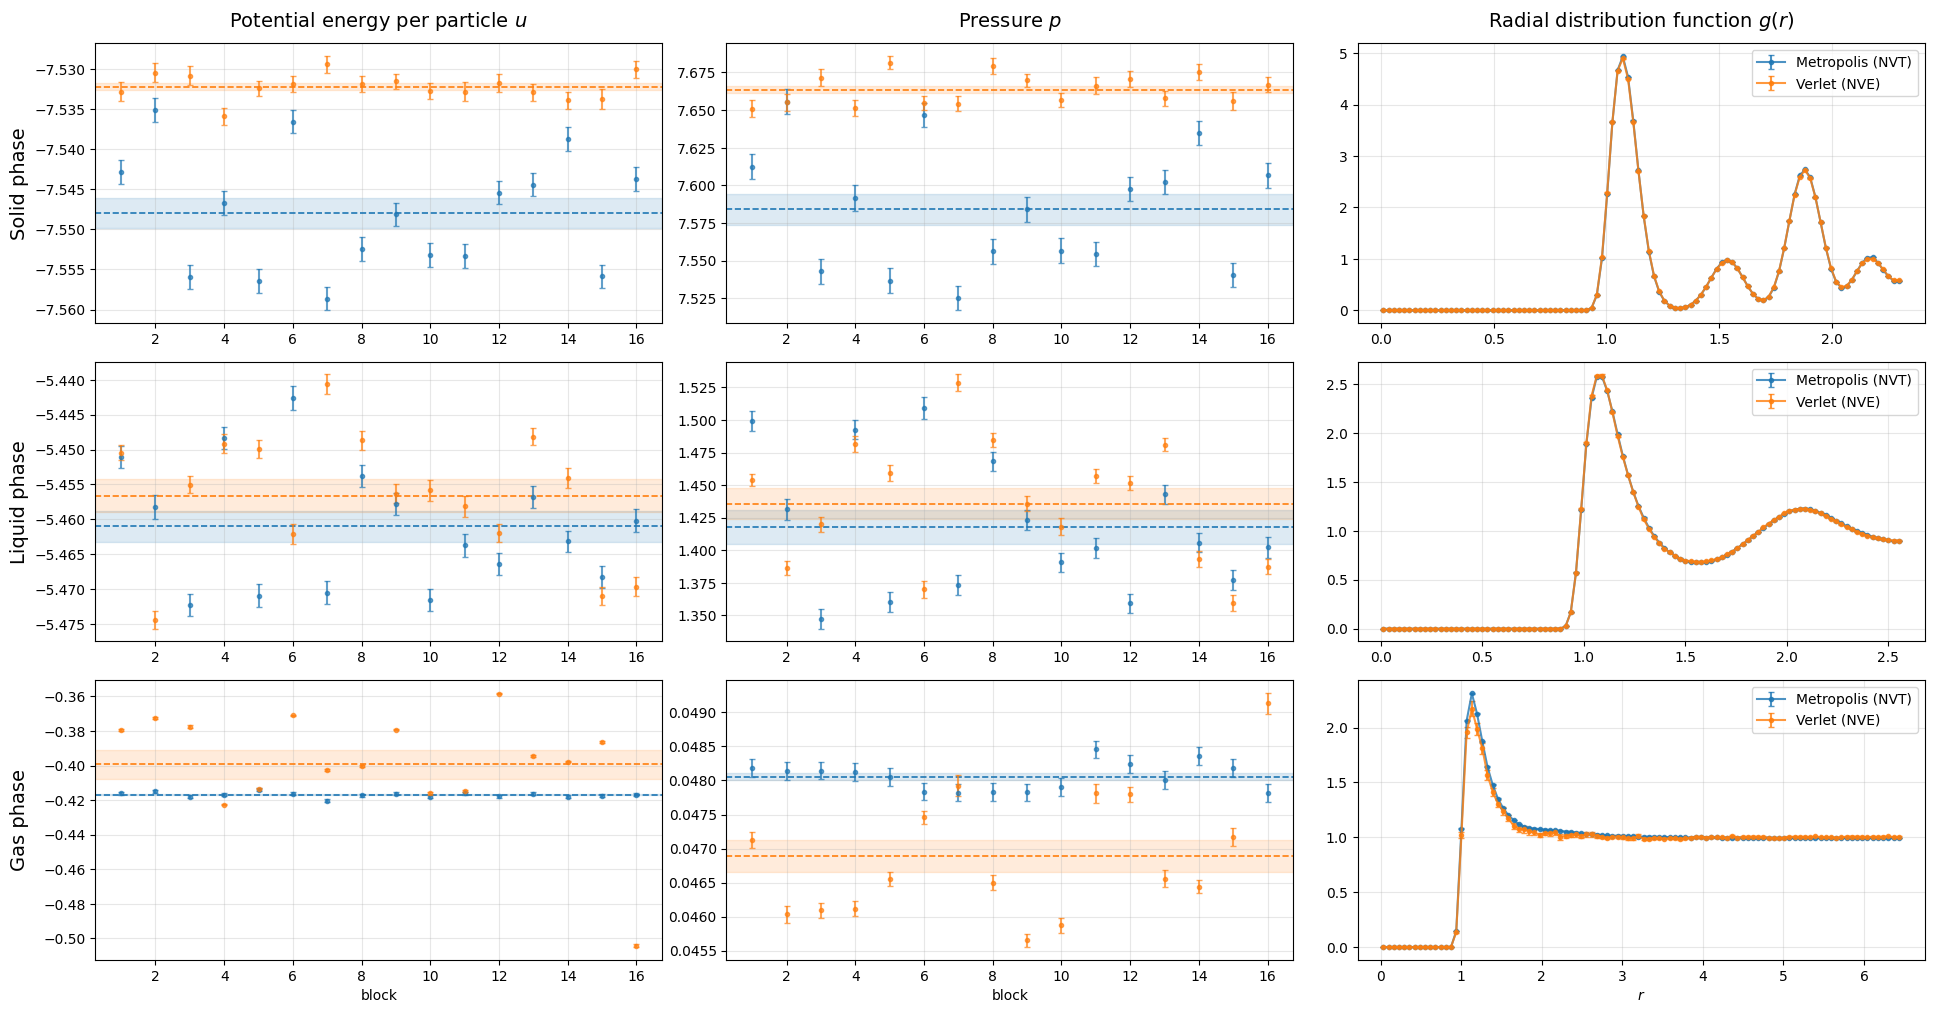

In [21]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = "sim_results/ex7"
PHASES = ["SOLID", "LIQUID", "GAS"]
METHODS = {"METROPOLIS": "Metropolis (NVT)", "VERLET": "Verlet (NVE)"}

def read_series(path):
    df = pd.read_csv(path)
    x, y, y_err = df.iloc[:, 0], df.iloc[:, 1], df.iloc[:, 2]
    avg, avg_err = df.iloc[-1, 3], df.iloc[-1, 4]
    return x, y, y_err, avg, avg_err

def read_box_dim(path):
    with open(path) as f:
        for line in f:
            m = re.search(r"BOX_DIM:\s*([-+0-9.eE]+)", line)
            if m:
                return float(m.group(1))

fig, axs = plt.subplots(len(PHASES), 3, figsize=(20, 10), squeeze=False)

for phase_id, phase in enumerate(PHASES):
    ax_u, ax_p, ax_g = axs[phase_id]
    for method_id, (key, label) in enumerate(METHODS.items()):
        d = f"{BASE}/{key}_{phase}"
        c = f"C{method_id}"

        # full series (points + errors) vs final average (line + error band)
        for ax, fname in ((ax_u, "potential_energy_per_particle.csv"),
                          (ax_p, "pressure.csv")):
            x, y, y_err, avg, avg_err = read_series(f"{d}/{fname}")
            ax.errorbar(x, y, yerr=y_err, fmt="o", ms=3, capsize=2,
                        color=c, alpha=0.7, label=label)
            ax.axhline(avg, color=c, ls="--", lw=1.2)
            ax.axhspan(avg - avg_err, avg + avg_err, color=c, alpha=0.15)

        r_max = read_box_dim(f"{d}/logfile.log") / 2
        g = pd.read_csv(f"{d}/gofr_global.csv")
        n = len(g)
        r = (np.arange(n) + 0.5) * (r_max / n)
        ax_g.errorbar(r, g["GLOBAL_AV"], yerr=g["ERROR"], fmt=".-",
                      capsize=2, color=c, label=label, alpha=0.8)

    for ax in (ax_u, ax_p, ax_g):
        ax.grid(alpha=0.3)
    ax_g.legend()

col_labels = [f"Potential energy per particle $u$", f"Pressure $p$", f"Radial distribution function $g(r)$"]
row_labels = ["Solid phase", "Liquid phase", "Gas phase"]
fig.tight_layout(rect=(0.04, 0, 1, 0.97))

for ax, label in zip(axs[0], col_labels):
    ax.annotate(label, xy=(0.5, 1), xytext=(0, 12),
                xycoords='axes fraction', textcoords='offset points',
                ha='center', va='baseline', fontsize=14)

for ax, label in zip(axs[:, 0], row_labels):
    pos = ax.get_position()
    fig.text(0.04, (pos.y0 + pos.y1) / 2, label,
             rotation=90, ha='center', va='center', fontsize=14)

axs[2][0].set_xlabel("block")
axs[2][1].set_xlabel("block")
axs[2][2].set_xlabel(f"$r$")

The pictures in the first column ($U/N$) and second column ($p$) show each block estimate with its error bar. The dotted lines mark the final block average with its error estimate.

Note that the simulations are first ran in Verlet mode (with the automatic thermalization process during the equilibration phase). Then the Verlet equilibration temperature is read from a logfile and used for its corresponding Metropolis run (*$NVT$ from the start, velocities are never changed*): this resulted in running simulations at
- $T^* = 0.8011$ for the solid phase (*$0.14\%$ higher than the proposed $T^* = 0.8$*)
- $T^* = 1.093$ for the liquid phase (*$0.64\%$ lower than the proposed $T^* = 1.1$*)
- $T^* = 1.187$ for the gas phase (*$1.0\%$ lower than the proposed $T^* = 1.2$*)

With these corrections, we can compare them:
- MC (Metropolis, *NVT*): we have generally lower values, with more stability in the gas phase and more fluctuations in the solid phase
- MD (Verlet, *NVE*): generally higher values, more fluctuations in the gas phase and stability in the solid phase

Globally, the relative distance from the two methods'results gets lower going from gas phase to solid phase.

Lastly, the *radial distribution functions* $g(r)$ obtained from the two methods are practically identical in all three phases.